<a href="https://colab.research.google.com/github/naylaakas/PembelajaranMesin-2026/blob/main/JS09/Tugas1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Buatlah model klasifikasi dengan menggunakan kNN untuk mengklasifikasikan jenis suara male dan female pada dataset voice.csv.

In [26]:
# Load data
import pandas as pd
data = pd.read_csv('voice.csv')
data.head()

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


In [27]:
# Preprocessing

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = data.iloc[:, :-1]   # semua kolom kecuali label
y = data.iloc[:, -1]    # kolom label terakhir

# Split data (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Standardisasi
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [28]:
# Buat Model kNN

from sklearn.neighbors import KNeighborsClassifier

# Tentukan nilai K (misalnya 3)
knn = KNeighborsClassifier(n_neighbors=3)

# Latih model
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

In [29]:
# Evaluasi Model kNN

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred = knn.predict(X_test)
print("Akurasi:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Laporan Klasifikasi:\n", classification_report(y_test, y_pred))

Akurasi: 0.9768664563617245
Confusion Matrix:
 [[440  12]
 [ 10 489]]
Laporan Klasifikasi:
               precision    recall  f1-score   support

      female       0.98      0.97      0.98       452
        male       0.98      0.98      0.98       499

    accuracy                           0.98       951
   macro avg       0.98      0.98      0.98       951
weighted avg       0.98      0.98      0.98       951



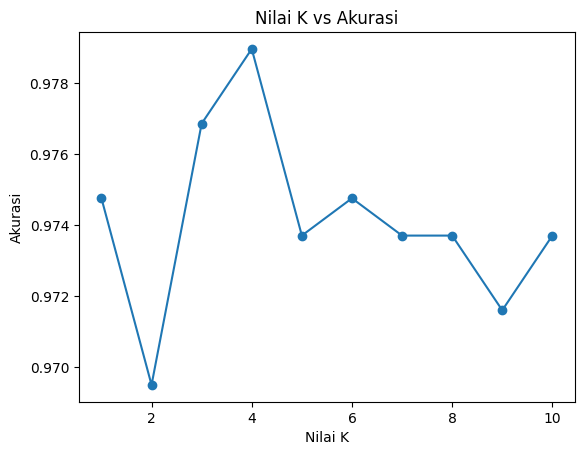

In [30]:
# Evaluasi setiap nilai k

acc = []
for k in range(1, 11):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    acc.append(model.score(X_test, y_test))

plt.plot(range(1, 11), acc, marker='o')
plt.title('Nilai K vs Akurasi')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.show()


2. Lakukan percobaan untuk mengetahui fitur-fitur yang paling optimal untuk digunakan. Fitur apa saja yang Anda gunakan untuk mendapatkan hasil terbaik?

In [36]:
from sklearn.feature_selection import SelectKBest, f_classif
import numpy as np

# 1. Hitung F-Score untuk ranking fitur
selector = SelectKBest(score_func=f_classif, k='all')
selector.fit(X_train, y_train)

feature_scores = pd.DataFrame({
    'Feature': X.columns,
    'Score': selector.scores_
}).sort_values(by='Score', ascending=False)

print("--- Ranking Fitur Teratas ---")
print(feature_scores.head(10).to_string(index=False))

# 2. Cari kombinasi fitur paling optimal
acc_results = []
for k_feat in range(1, len(X.columns) + 1):
    top_feats = feature_scores['Feature'].head(k_feat).tolist()

    # Fit & test hanya dengan top_feats (pake scaler yang udah ada atau fit ulang subset)
    X_tr_sub = scaler.fit_transform(X_train[top_feats])
    X_te_sub = scaler.transform(X_test[top_feats])

    knn_temp = KNeighborsClassifier(n_neighbors=3)
    knn_temp.fit(X_tr_sub, y_train)
    acc_results.append((k_feat, knn_temp.score(X_te_sub, y_test), top_feats))

best_num, best_acc, best_features = max(acc_results, key=lambda item: item[1])

print(f"\nAkurasi Terbaik: {best_acc * 100:.2f}%")
print(f"Jumlah Fitur Optimal: {best_num} fitur")
print("Daftar Fitur Terpilih:", best_features)

--- Ranking Fitur Teratas ---
 Feature       Score
 meanfun 5029.522726
     IQR 1327.392845
     Q25  744.373408
  sp.ent  686.673230
      sd  631.538022
     sfm  305.745649
centroid  261.915407
meanfreq  261.915407
  median  172.938508
 meandom   87.002711

Akurasi Terbaik: 98.11%
Jumlah Fitur Optimal: 7 fitur
Daftar Fitur Terpilih: ['meanfun', 'IQR', 'Q25', 'sp.ent', 'sd', 'sfm', 'centroid']
